# Phase 2 Rainfall Analysis

In this notebook, we explore the processed NASA GPM IMERG rainfall data for the United States. Our goal is to study how rainfall frequency, rainfall intensity, and heavy rainfall changed across time and location during our study period.

The processed data is used for all analysis in this notebook.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

analytics_dir = project_root / "data" / "analytics"

sample_path = analytics_dir / "eda_sample.parquet"

df = pd.read_parquet(sample_path)

print("Shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nColumns:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

Shape: (413400, 7)

First 5 rows:
    latitude   longitude  precipitation_mm_per_hr                  datetime  \
0  30.549999 -108.849998                     0.00 2025-08-02 22:30:00+00:00   
1  32.750000 -110.250000                     0.08 2025-08-02 22:30:00+00:00   
2  31.250000  -77.150002                     1.79 2025-08-02 22:30:00+00:00   
3  42.549999 -120.949997                     0.00 2025-08-02 22:30:00+00:00   
4  41.149998 -101.949997                     0.00 2025-08-02 22:30:00+00:00   

         date  hour  minute  
0  2025-08-02    22      30  
1  2025-08-02    22      30  
2  2025-08-02    22      30  
3  2025-08-02    22      30  
4  2025-08-02    22      30  

Columns:
Index(['latitude', 'longitude', 'precipitation_mm_per_hr', 'datetime', 'date',
       'hour', 'minute'],
      dtype='str')

Missing values:
latitude                   0
longitude                  0
precipitation_mm_per_hr    0
datetime                   0
date                       0
hour           

# Processed Data Check

The EDA sample contains 413,400 observations. We checked the columns and missing values before starting the analysis. This helps us make sure the processed data is ready to use.

In [9]:
rainy_data = df[
    df["precipitation_mm_per_hr"] > 0
].copy()

print("Total sample observations:", len(df))

print("Rainy observations:", len(rainy_data))

print(
    "Percentage of rainy observations:",
    (len(rainy_data) / len(df)) * 100
)

print("\nRainfall percentiles:")

print(
    rainy_data["precipitation_mm_per_hr"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Total sample observations: 413400
Rainy observations: 40935
Percentage of rainy observations: 9.902031930333816

Rainfall percentiles:
0.50     0.4900
0.75     1.4700
0.90     3.4600
0.95     5.3000
0.99    11.4866
Name: precipitation_mm_per_hr, dtype: float64


About 9.9% of the sampled observations had rainfall above 0 mm/hr. Most observations did not have rain. We also checked the rainfall percentiles to understand the distribution of positive rainfall values.

In [10]:
heavy_rain_threshold = 5.3

df["heavy_rain"] = (
    df["precipitation_mm_per_hr"] >= heavy_rain_threshold
)

print("Heavy rainfall threshold:", heavy_rain_threshold, "mm/hr")

print(
    "Heavy rainfall observations:",
    df["heavy_rain"].sum()
)

print(
    "Heavy rainfall percentage:",
    df["heavy_rain"].mean() * 100
)

Heavy rainfall threshold: 5.3 mm/hr
Heavy rainfall observations: 2044
Heavy rainfall percentage: 0.4944363812288341


# Heavy Rainfall Definition

For this project, we define heavy rainfall as precipitation of 5.3 mm/hr or higher. This value is the 95th percentile of the positive rainfall observations in our processed sample.

This is a threshold used for our study period. We are not using it as a general definition of heavy rainfall for every weather study.

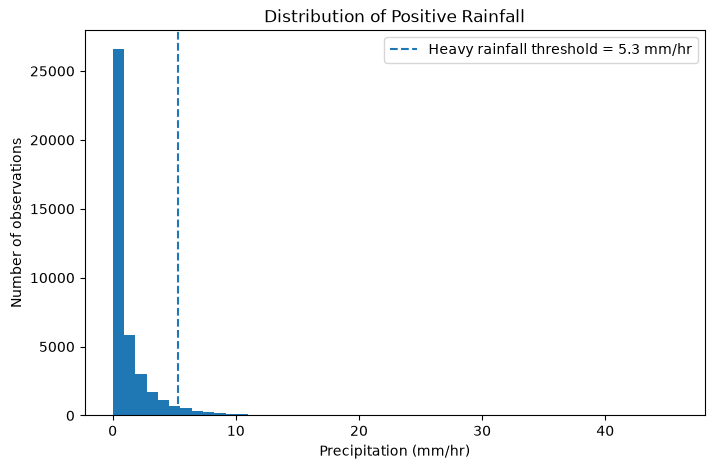

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(
    rainy_data["precipitation_mm_per_hr"],
    bins=50
)

plt.axvline(
    heavy_rain_threshold,
    linestyle="--",
    label="Heavy rainfall threshold = 5.3 mm/hr"
)

plt.xlabel("Precipitation (mm/hr)")
plt.ylabel("Number of observations")
plt.title("Distribution of Positive Rainfall")

plt.legend()

plt.show()

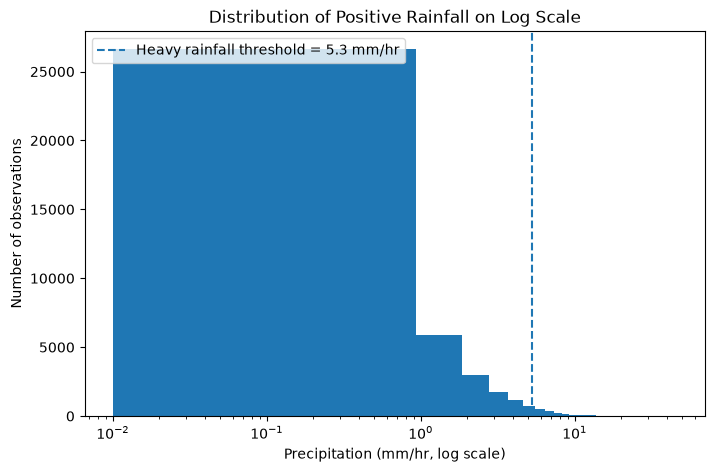

In [12]:
plt.figure(figsize=(8, 5))

plt.hist(
    rainy_data["precipitation_mm_per_hr"],
    bins=50
)

plt.axvline(
    heavy_rain_threshold,
    linestyle="--",
    label="Heavy rainfall threshold = 5.3 mm/hr"
)

plt.xscale("log")

plt.xlabel("Precipitation (mm/hr, log scale)")
plt.ylabel("Number of observations")
plt.title("Distribution of Positive Rainfall on Log Scale")

plt.legend()

plt.show()

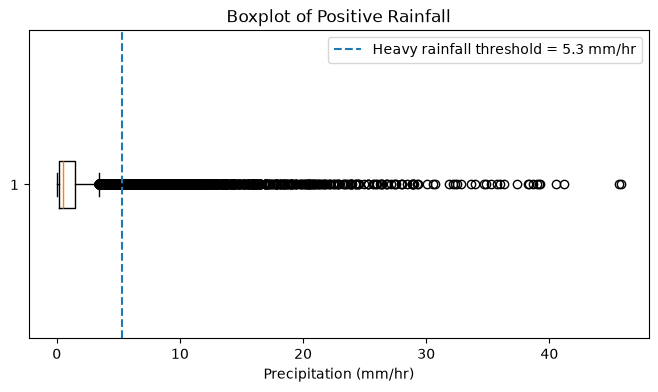

In [13]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    rainy_data["precipitation_mm_per_hr"],
    orientation="horizontal"
)

plt.axvline(
    heavy_rain_threshold,
    linestyle="--",
    label="Heavy rainfall threshold = 5.3 mm/hr"
)

plt.xlabel("Precipitation (mm/hr)")
plt.title("Boxplot of Positive Rainfall")

plt.legend()

plt.show()

In [14]:
rain_summary = rainy_data["precipitation_mm_per_hr"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print(rain_summary)

count    40935.000000
mean         1.341944
std          2.467380
min          0.010000
25%          0.170000
50%          0.490000
75%          1.470000
90%          3.460000
95%          5.300000
99%         11.486600
max         45.779999
Name: precipitation_mm_per_hr, dtype: float64


# Rainfall Distribution

The positive rainfall values are strongly right-skewed. Most rainfall values are small, while a smaller number of observations have much higher rainfall intensity.

The boxplot also shows many high values. We kept these values because strong rainfall events are important for our research question and should not automatically be treated as errors.

# Daily Rainfall Analysis

Next, we study how rainfall changed from day to day. We first check whether every day has complete data before comparing the daily results.

In [ ]:
daily_path = analytics_dir / "daily_summary.parquet"

daily_df = pd.read_parquet(daily_path)

print("Shape:", daily_df.shape)

print("\nFirst 5 rows:")
print(daily_df.head())

print("\nColumns:")
print(daily_df.columns)

Shape: (44, 9)

First 5 rows:
         date  total_rows  rainy_rows  heavy_rain_rows  average_precipitation  \
0  2025-08-02      460200       53102             2367               0.159508   
1  2025-08-03     7363200      646092            30739               0.114976   
2  2025-08-04     7363200      531757            24969               0.088089   
3  2025-08-05     7363200      437882            18800               0.073313   
4  2025-08-06     7363200      458273            21014               0.075467   

   average_rainy_precipitation  maximum_precipitation  rain_percentage  \
0                     1.382486              43.529999        11.538896   
1                     1.316196              47.239998         8.774609   
2                     1.229255              51.439999         7.221819   
3                     1.236250              41.110001         5.946898   
4                     1.237841              36.450001         6.223829   

   heavy_rain_percentage  
0          

In [16]:
daily_df["files_available"] = (
    daily_df["total_rows"] / 153400
).astype(int)

daily_df["coverage_percentage"] = (
    daily_df["files_available"] / 48
) * 100

print(
    daily_df[
        ["date", "files_available", "coverage_percentage"]
    ]
)

          date  files_available  coverage_percentage
0   2025-08-02                3                 6.25
1   2025-08-03               48               100.00
2   2025-08-04               48               100.00
3   2025-08-05               48               100.00
4   2025-08-06               48               100.00
5   2025-08-07               48               100.00
6   2025-08-08               48               100.00
7   2025-08-09               48               100.00
8   2025-08-10               48               100.00
9   2025-08-11               48               100.00
10  2025-08-12               48               100.00
11  2025-08-13               48               100.00
12  2025-08-14               48               100.00
13  2025-08-15               48               100.00
14  2025-08-16               48               100.00
15  2025-08-17               48               100.00
16  2025-08-18               48               100.00
17  2025-08-19               48               

In [17]:
complete_daily_df = daily_df[
    daily_df["files_available"] == 48
].copy()

print("Complete days:", len(complete_daily_df))

print("First date:", complete_daily_df["date"].min())
print("Last date:", complete_daily_df["date"].max())


Complete days: 43
First date: 2025-08-03
Last date: 2025-09-14


# Daily Data Coverage

The requested study period was August 1 to September 14, 2025. However, the downloaded data is incomplete at the beginning of the period.

August 1 has no data, and August 2 has only 3 of the expected 48 half-hour files. Because of this, we use the 43 complete days from August 3 to September 14 for daily comparisons.

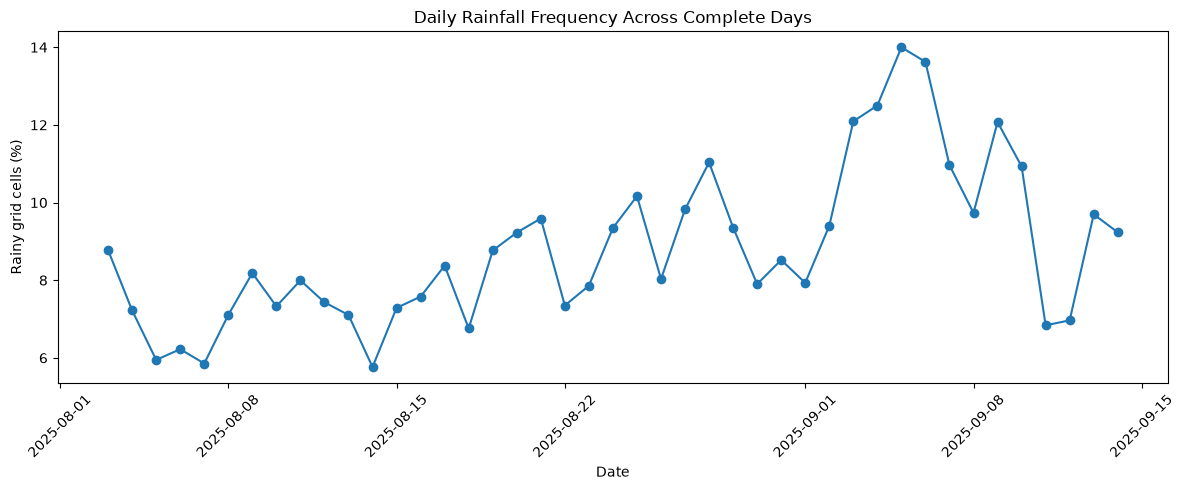

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(
    complete_daily_df["date"],
    complete_daily_df["rain_percentage"],
    marker="o"
)

plt.xlabel("Date")
plt.ylabel("Rainy grid cells (%)")
plt.title("Daily Rainfall Frequency Across Complete Days")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


In [19]:
highest_rain_days = complete_daily_df.nlargest(
    5,
    "rain_percentage"
)[["date", "rain_percentage"]]

print("Top 5 days with highest rainfall frequency:")
print(highest_rain_days)

print()


lowest_rain_days = complete_daily_df.nsmallest(
    5,
    "rain_percentage"
)[["date", "rain_percentage"]]

print("Top 5 days with lowest rainfall frequency:")
print(lowest_rain_days)

Top 5 days with highest rainfall frequency:
          date  rain_percentage
34  2025-09-05        13.997800
35  2025-09-06        13.623927
33  2025-09-04        12.499280
32  2025-09-03        12.091672
38  2025-09-09        12.072319

Top 5 days with lowest rainfall frequency:
          date  rain_percentage
12  2025-08-14         5.763771
5   2025-08-07         5.855009
3   2025-08-05         5.946898
4   2025-08-06         6.223829
16  2025-08-18         6.757673


Rainfall frequency changed across the complete days. September 5 had the highest rainfall frequency at about 14.0%. September 6 and September 4 were also among the highest days.

This means rainfall was observed more often across the grid and time observations on these days.

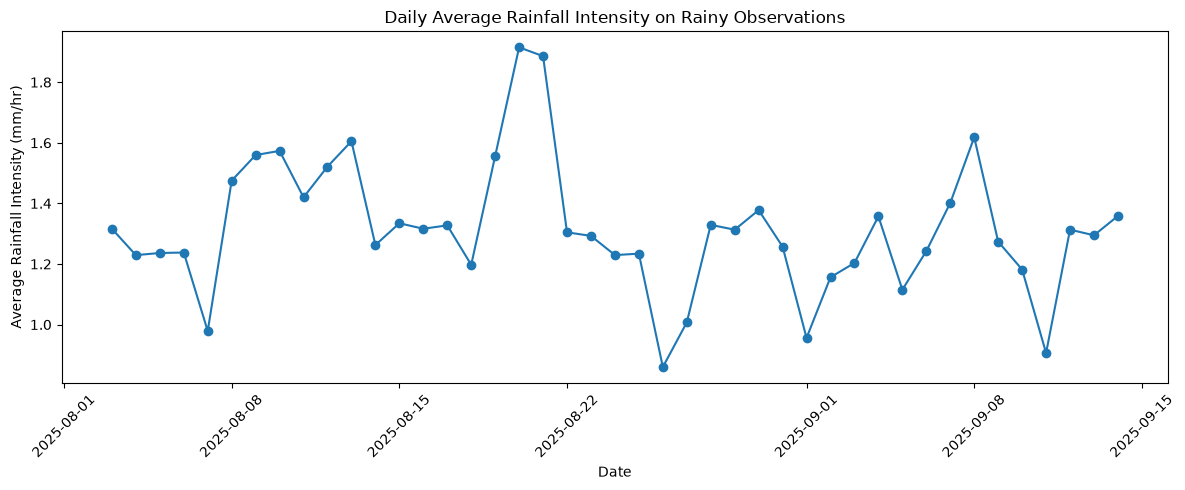

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(
    complete_daily_df["date"],
    complete_daily_df["average_rainy_precipitation"],
    marker="o"
)

plt.xlabel("Date")
plt.ylabel("Average Rainfall Intensity (mm/hr)")
plt.title("Daily Average Rainfall Intensity on Rainy Observations")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [21]:
highest_intensity_days = complete_daily_df.nlargest(
    5,
    "average_rainy_precipitation"
)[["date", "average_rainy_precipitation"]]

print("Top 5 days with highest average rainfall intensity:")
print(highest_intensity_days)

Top 5 days with highest average rainfall intensity:
          date  average_rainy_precipitation
18  2025-08-20                     1.915106
19  2025-08-21                     1.885917
37  2025-09-08                     1.618183
11  2025-08-13                     1.604984
8   2025-08-10                     1.573370


August 20 and August 21 had the highest average rainfall intensity on rainy observations. This shows that these days had stronger rainfall when rain was present.

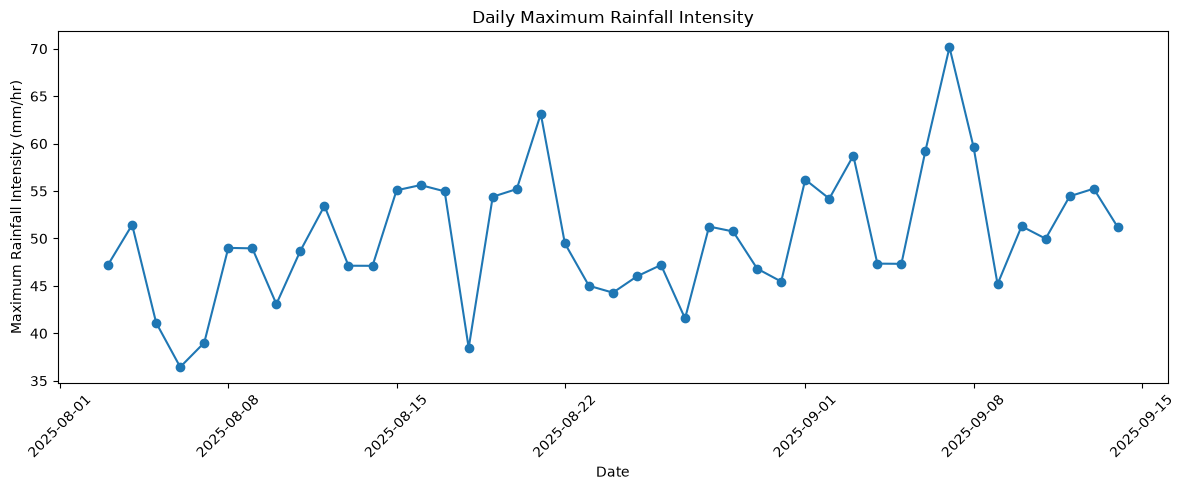

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(
    complete_daily_df["date"],
    complete_daily_df["maximum_precipitation"],
    marker="o"
)

plt.xlabel("Date")
plt.ylabel("Maximum Rainfall Intensity (mm/hr)")
plt.title("Daily Maximum Rainfall Intensity")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [23]:
highest_max_days = complete_daily_df.nlargest(
    5,
    "maximum_precipitation"
)[["date", "maximum_precipitation"]]

print("Top 5 days with highest maximum rainfall intensity:")
print(highest_max_days)

Top 5 days with highest maximum rainfall intensity:
          date  maximum_precipitation
36  2025-09-07              70.150002
19  2025-08-21              63.129997
37  2025-09-08              59.660000
35  2025-09-06              59.250000
32  2025-09-03              58.730000


The maximum rainfall value also changed across days. The highest daily maximum was about 70.15 mm/hr on September 7.

This value represents the strongest single grid-cell rainfall rate recorded on that day. It does not represent the average rainfall across the United States.

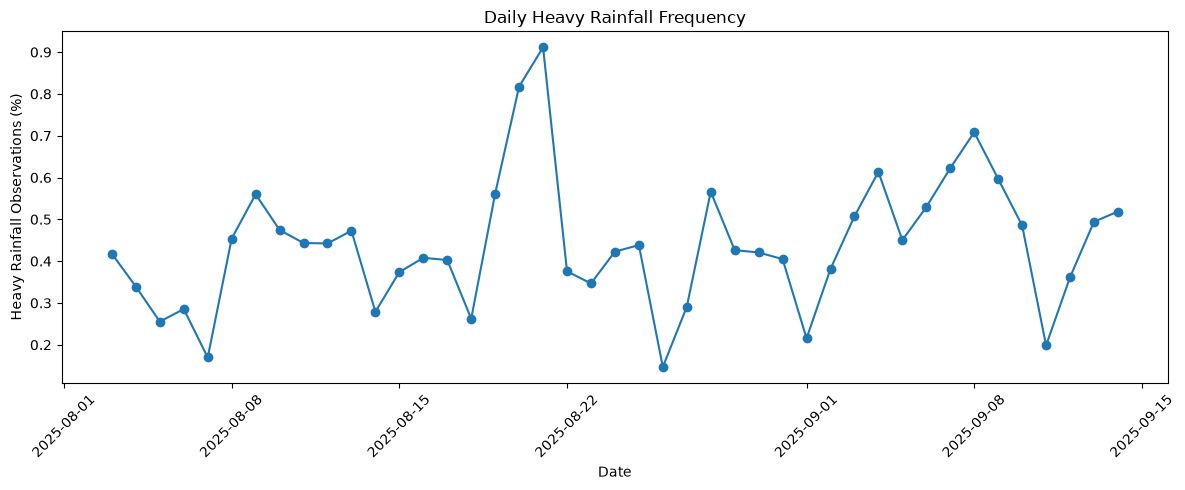

In [24]:
plt.figure(figsize=(12, 5))

plt.plot(
    complete_daily_df["date"],
    complete_daily_df["heavy_rain_percentage"],
    marker="o"
)

plt.xlabel("Date")
plt.ylabel("Heavy Rainfall Observations (%)")
plt.title("Daily Heavy Rainfall Frequency")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [25]:
highest_heavy_rain_days = complete_daily_df.nlargest(
    5,
    "heavy_rain_percentage"
)[["date", "heavy_rain_rows", "heavy_rain_percentage"]]

print("Top 5 days with highest heavy rainfall frequency:")
print(highest_heavy_rain_days)

Top 5 days with highest heavy rainfall frequency:
          date  heavy_rain_rows  heavy_rain_percentage
19  2025-08-21            67110               0.911424
18  2025-08-20            60206               0.817661
37  2025-09-08            52147               0.708211
36  2025-09-07            45836               0.622501
33  2025-09-04            45181               0.613605


In [26]:
lowest_heavy_rain_days = complete_daily_df.nsmallest(
    5,
    "heavy_rain_percentage"
)[["date", "heavy_rain_rows", "heavy_rain_percentage"]]

print("Top 5 days with lowest heavy rainfall frequency:")
print(lowest_heavy_rain_days)

Top 5 days with lowest heavy rainfall frequency:
          date  heavy_rain_rows  heavy_rain_percentage
24  2025-08-26            10803               0.146716
5   2025-08-07            12487               0.169587
40  2025-09-11            14619               0.198541
30  2025-09-01            15856               0.215341
3   2025-08-05            18800               0.255324


# Daily Heavy Rainfall

Heavy rainfall also changed across the study period. August 21 had the highest heavy rainfall frequency, followed by August 20.

These two days also had high average rainfall intensity. This suggests that rainfall on these days was not only present, but was also stronger than on many other days.

In [27]:
comparison_df = complete_daily_df[
    ["rain_percentage", "heavy_rain_percentage"]
].copy()

print(comparison_df.corr())

                       rain_percentage  heavy_rain_percentage
rain_percentage               1.000000               0.537172
heavy_rain_percentage         0.537172               1.000000


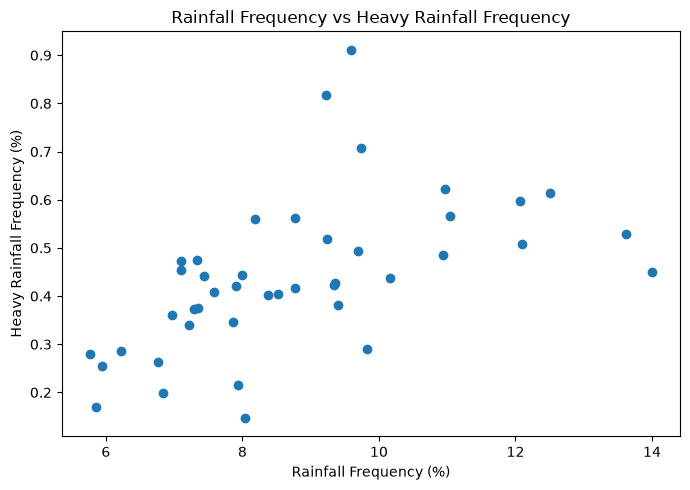

In [28]:
plt.figure(figsize=(7, 5))

plt.scatter(
    complete_daily_df["rain_percentage"],
    complete_daily_df["heavy_rain_percentage"]
)

plt.xlabel("Rainfall Frequency (%)")
plt.ylabel("Heavy Rainfall Frequency (%)")
plt.title("Rainfall Frequency vs Heavy Rainfall Frequency")

plt.tight_layout()

plt.show()

The correlation between overall rainfall frequency and heavy rainfall frequency is about 0.54. This is a moderate positive relationship.

Days with more rainfall usually had more heavy rainfall, but the relationship is not perfect. A day can have frequent rainfall without having the highest amount of heavy rainfall.

# Hourly Rainfall Analysis

We next study rainfall by hour of the day. The time values in the NASA IMERG data are in UTC, so the hourly results below are also shown in UTC.

In [ ]:
hourly_path = analytics_dir / "hourly_summary.parquet"

hourly_df = pd.read_parquet(hourly_path)

print("Shape:", hourly_df.shape)

print("\nFirst 5 rows:")
print(hourly_df.head())

print("\nColumns:")
print(hourly_df.columns)

Shape: (24, 5)

First 5 rows:
   hour  average_rain_percentage  average_precipitation  \
0     0                10.478237               0.122738   
1     1                 9.392749               0.113073   
2     2                 8.361094               0.104458   
3     3                 7.777675               0.099949   
4     4                 7.877861               0.098031   

   average_rainy_precipitation  maximum_precipitation  
0                     1.182831              47.119999  
1                     1.219884              49.739998  
2                     1.268357              50.739998  
3                     1.301408              49.730000  
4                     1.243771              54.449997  

Columns:
Index(['hour', 'average_rain_percentage', 'average_precipitation',
       'average_rainy_precipitation', 'maximum_precipitation'],
      dtype='str')


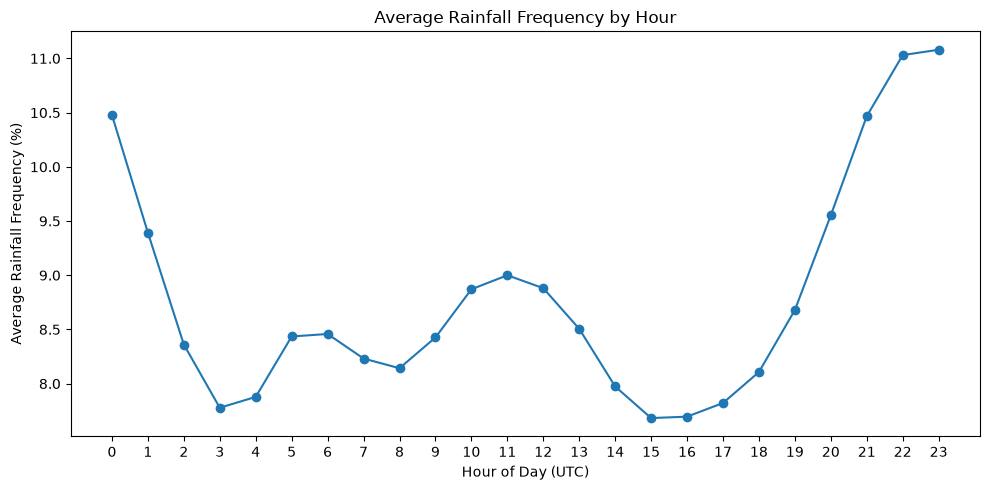

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_df["hour"],
    hourly_df["average_rain_percentage"],
    marker="o"
)

plt.xlabel("Hour of Day (UTC)")
plt.ylabel("Average Rainfall Frequency (%)")
plt.title("Average Rainfall Frequency by Hour")

plt.xticks(range(0, 24))

plt.tight_layout()

plt.show()

In [31]:
highest_hourly_frequency = hourly_df.nlargest(
    5,
    "average_rain_percentage"
)[["hour", "average_rain_percentage"]]

print("Top 5 hours with highest rainfall frequency:")
print(highest_hourly_frequency)

print()

lowest_hourly_frequency = hourly_df.nsmallest(
    5,
    "average_rain_percentage"
)[["hour", "average_rain_percentage"]]

print("Top 5 hours with lowest rainfall frequency:")
print(lowest_hourly_frequency)

Top 5 hours with highest rainfall frequency:
    hour  average_rain_percentage
23    23                11.080079
22    22                11.030729
0      0                10.478237
21    21                10.467261
20    20                 9.553584

Top 5 hours with lowest rainfall frequency:
    hour  average_rain_percentage
15    15                 7.682431
16    16                 7.695499
3      3                 7.777675
17    17                 7.821435
4      4                 7.877861


Rainfall frequency was highest mainly around 21:00 to 23:00 UTC. The lowest rainfall frequencies were mainly around 15:00 to 17:00 UTC.

These hours are shown in UTC and should not be treated as local time for every part of the United States.

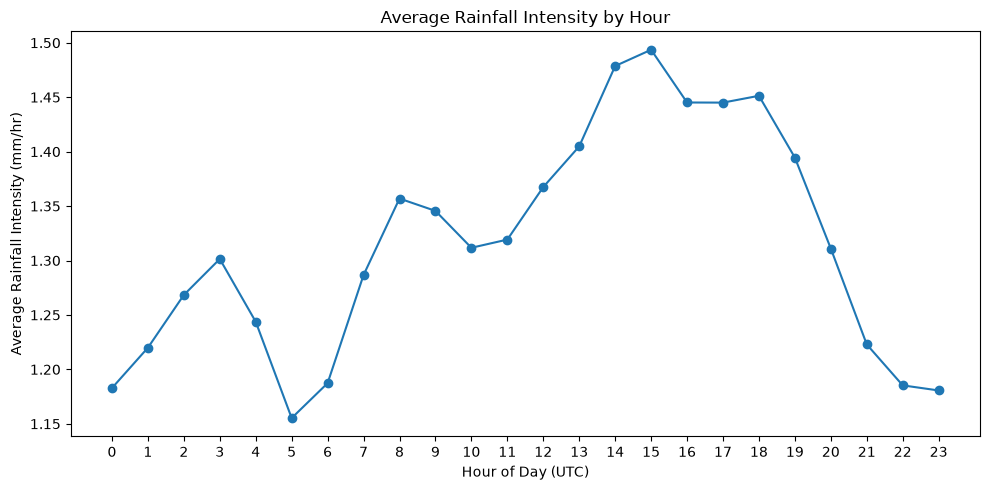

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_df["hour"],
    hourly_df["average_rainy_precipitation"],
    marker="o"
)

plt.xlabel("Hour of Day (UTC)")
plt.ylabel("Average Rainfall Intensity (mm/hr)")
plt.title("Average Rainfall Intensity by Hour")

plt.xticks(range(0, 24))

plt.tight_layout()

plt.show()

In [33]:
highest_hourly_intensity = hourly_df.nlargest(
    5,
    "average_rainy_precipitation"
)[["hour", "average_rainy_precipitation"]]

print("Top 5 hours with highest average rainfall intensity:")
print(highest_hourly_intensity)

print()

lowest_hourly_intensity = hourly_df.nsmallest(
    5,
    "average_rainy_precipitation"
)[["hour", "average_rainy_precipitation"]]

print("Top 5 hours with lowest average rainfall intensity:")
print(lowest_hourly_intensity)

Top 5 hours with highest average rainfall intensity:
    hour  average_rainy_precipitation
15    15                     1.493592
14    14                     1.478648
18    18                     1.451303
16    16                     1.445150
17    17                     1.445037

Top 5 hours with lowest average rainfall intensity:
    hour  average_rainy_precipitation
5      5                     1.155270
23    23                     1.180636
0      0                     1.182831
22    22                     1.185319
6      6                     1.187358


Average rainfall intensity showed a different hourly pattern. The highest average intensity was mainly around 14:00 to 18:00 UTC.

This is different from rainfall frequency, which was highest later in the day. This shows that the time when rainfall happened most often was not the same as the time when rainfall was strongest.

# Spatial Rainfall Analysis

The rainfall data was grouped into 1-degree latitude and longitude bins to study geographic patterns.

The original rainfall area is rectangular, so it also contains ocean areas and locations outside the lower 48 states. We therefore use U.S. state boundaries to keep only spatial bins whose center point falls inside the lower 48 states.

In [ ]:
spatial_path = analytics_dir / "spatial_summary.parquet"

spatial_df = pd.read_parquet(spatial_path)

print("Shape:", spatial_df.shape)

print("\nFirst 5 rows:")
print(spatial_df.head())

print("\nColumns:")
print(spatial_df.columns)

Shape: (1534, 10)

First 5 rows:
   latitude_bin  longitude_bin  total_observations  rainy_observations  \
0          24.0         -125.0              206700                3256   
1          24.0         -124.0              206700                7170   
2          24.0         -123.0              206700                7340   
3          24.0         -122.0              206700                6368   
4          24.0         -121.0              206700                7835   

   heavy_rain_observations  precipitation_sum  maximum_precipitation  \
0                        0         353.970001                   1.39   
1                        0         829.849976                   1.10   
2                        0        1557.069946                   2.87   
3                        0        1360.309937                   2.18   
4                       55        3350.000000                  18.32   

   rain_frequency_percent  heavy_rain_frequency_percent  average_precipitation  
0       

In [ ]:
import shapefile
from matplotlib.path import Path as MplPath

In [ ]:
shapefile_path = (
    project_root
    / "data"
    / "boundaries"
    / "tl_2025_us_state"
    / "tl_2025_us_state.shp"
)

In [37]:
sf = shapefile.Reader(str(shapefile_path))

print("Number of state shapes:", len(sf.shapes()))

Number of state shapes: 56


In [ ]:
from matplotlib.path import Path as MplPath
import numpy as np

excluded = ["AK", "HI", "PR", "VI", "GU", "MP", "AS"]

field_names = [field.name for field in sf.fields[1:]]

state_paths = []

for shape_record in sf.iterShapeRecords():
    record = dict(zip(field_names, shape_record.record))

    if record["STUSPS"] in excluded:
        continue

    shape = shape_record.shape
    points = np.array(shape.points)

    parts = list(shape.parts) + [len(points)]

    for i in range(len(parts) - 1):
        polygon_points = points[parts[i]:parts[i + 1]]

        if len(polygon_points) >= 3:
            state_paths.append(MplPath(polygon_points))

print("State polygon parts loaded:", len(state_paths))

State polygon parts loaded: 62


In [39]:
spatial_df["center_latitude"] = spatial_df["latitude_bin"] + 0.5
spatial_df["center_longitude"] = spatial_df["longitude_bin"] + 0.5

inside_us = []

for _, row in spatial_df.iterrows():
    point = (
        row["center_longitude"],
        row["center_latitude"]
    )

    is_inside = any(
        path.contains_point(point)
        for path in state_paths
    )

    inside_us.append(is_inside)

spatial_land = spatial_df[inside_us].copy()

print("Original spatial bins:", len(spatial_df))
print("Bins inside lower 48 states:", len(spatial_land))

Original spatial bins: 1534
Bins inside lower 48 states: 851


The original spatial summary contained 1,534 bins. After using the state boundaries, 851 bins remained inside the lower 48 states.

We use these 851 bins for the final spatial analysis so that ocean and other outside areas do not affect the results.

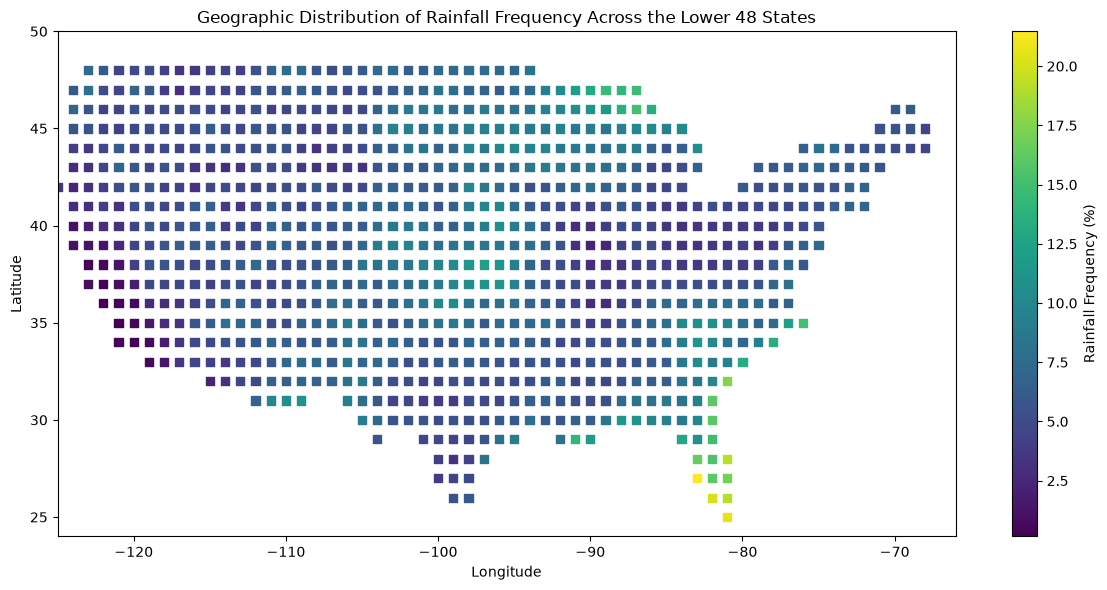

In [40]:
plt.figure(figsize=(12, 6))

plt.scatter(
    spatial_land["longitude_bin"],
    spatial_land["latitude_bin"],
    c=spatial_land["rain_frequency_percent"],
    cmap="viridis",
    s=35,
    marker="s"
)

plt.colorbar(label="Rainfall Frequency (%)")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of Rainfall Frequency Across the Lower 48 States")

plt.xlim(-125, -66)
plt.ylim(24, 50)

plt.tight_layout()

plt.show()

In [41]:
highest_frequency_locations = spatial_land.nlargest(
    10,
    "rain_frequency_percent"
)[
    [
        "latitude_bin",
        "longitude_bin",
        "rain_frequency_percent"
    ]
]

print("Top 10 spatial bins with highest rainfall frequency:")
print(highest_frequency_locations)

Top 10 spatial bins with highest rainfall frequency:
     latitude_bin  longitude_bin  rain_frequency_percent
219          27.0          -83.0               21.471214
103          25.0          -81.0               20.663280
161          26.0          -82.0               20.209966
162          26.0          -81.0               19.181422
280          28.0          -81.0               19.173198
516          32.0          -81.0               17.477987
221          27.0          -81.0               16.912917
278          28.0          -83.0               16.422835
397          30.0          -82.0               16.126754
220          27.0          -82.0               16.103532


# Geographic Rainfall Frequency

Rainfall frequency was highest mainly in Florida and parts of the southeastern United States during the study period.

The highest spatial bin had rainfall in about 21.47% of its observations. Most of the top rainfall-frequency bins were located around Florida.

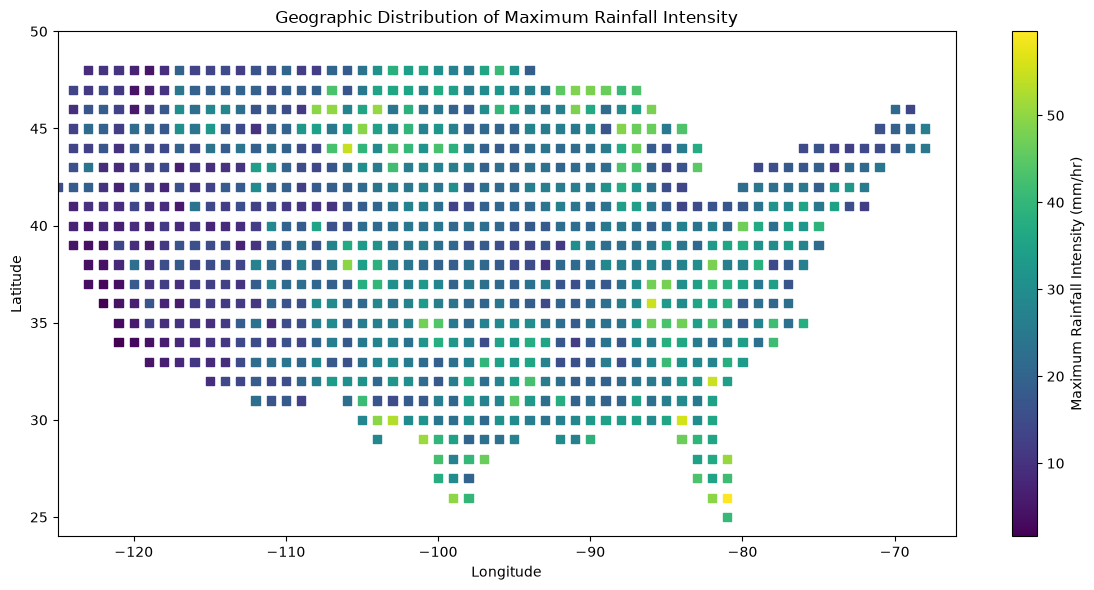

In [42]:
plt.figure(figsize=(12, 6))

plt.scatter(
    spatial_land["longitude_bin"],
    spatial_land["latitude_bin"],
    c=spatial_land["maximum_precipitation"],
    cmap="viridis",
    s=35,
    marker="s"
)

plt.colorbar(label="Maximum Rainfall Intensity (mm/hr)")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of Maximum Rainfall Intensity")

plt.xlim(-125, -66)
plt.ylim(24, 50)

plt.tight_layout()

plt.show()

In [43]:
highest_max_locations = spatial_land.nlargest(
    10,
    "maximum_precipitation"
)[
    [
        "latitude_bin",
        "longitude_bin",
        "maximum_precipitation"
    ]
]

print("Top 10 spatial bins with highest maximum rainfall intensity:")
print(highest_max_locations)

Top 10 spatial bins with highest maximum rainfall intensity:
      latitude_bin  longitude_bin  maximum_precipitation
162           26.0          -81.0              59.660000
395           30.0          -84.0              55.629997
515           32.0          -82.0              55.079998
747           36.0          -86.0              54.969997
1199          44.0         -106.0              54.449997
376           30.0         -103.0              53.009998
319           29.0         -101.0              50.939999
280           28.0          -81.0              50.739998
1319          46.0         -104.0              50.549999
1316          46.0         -107.0              49.980000


# Geographic Rainfall Intensity

The highest maximum rainfall intensity was about 59.66 mm/hr in Florida. However, other high maximum values were found in different parts of the country, including the Southeast, Texas, Tennessee, Wyoming, and Montana.

This pattern is different from rainfall frequency. Frequent rainfall was more concentrated around Florida, while very strong individual rainfall events were more spread out.

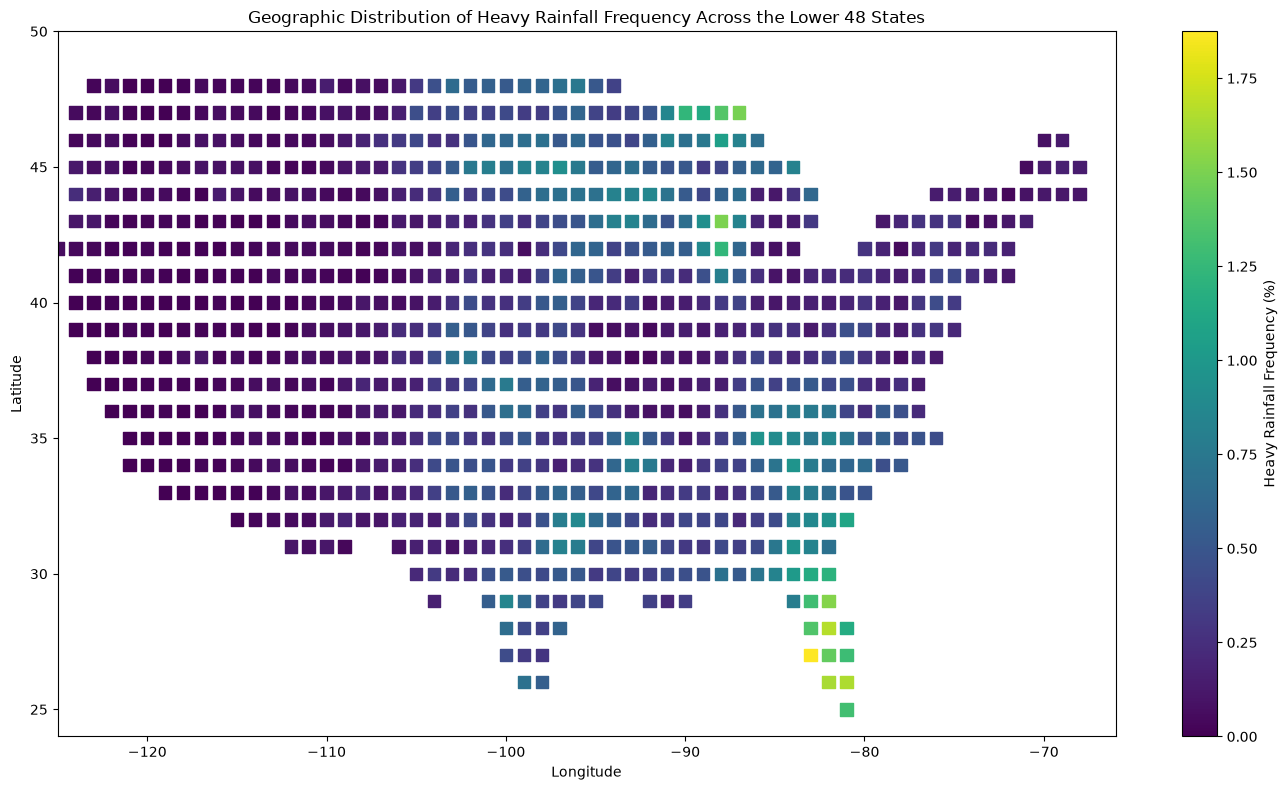

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

plt.scatter(
    spatial_land["longitude_bin"],
    spatial_land["latitude_bin"],
    c=spatial_land["heavy_rain_frequency_percent"],
    cmap="viridis",
    s=80,
    marker="s"
)

plt.colorbar(label="Heavy Rainfall Frequency (%)")
plt.title("Geographic Distribution of Heavy Rainfall Frequency Across the Lower 48 States")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.xlim(-125, -66)
plt.ylim(24, 50)
plt.tight_layout()
plt.show()

In [45]:
highest_heavy_frequency_locations = spatial_land.nlargest(
    10,
    "heavy_rain_frequency_percent"
)[
    [
        "latitude_bin",
        "longitude_bin",
        "heavy_rain_observations",
        "heavy_rain_frequency_percent"
    ]
]

print("Top 10 spatial bins with highest heavy rainfall frequency:")
print(highest_heavy_frequency_locations)

Top 10 spatial bins with highest heavy rainfall frequency:
      latitude_bin  longitude_bin  heavy_rain_observations  \
219           27.0          -83.0                     3875   
279           28.0          -82.0                     3438   
162           26.0          -81.0                     3403   
161           26.0          -82.0                     3374   
338           29.0          -82.0                     3158   
1158          43.0          -88.0                     3118   
1395          47.0          -87.0                     3074   
220           27.0          -82.0                     2939   
1394          47.0          -88.0                     2845   
278           28.0          -83.0                     2812   

      heavy_rain_frequency_percent  
219                       1.874698  
279                       1.663280  
162                       1.646347  
161                       1.632317  
338                       1.527818  
1158                      1.508466  

# Geographic Heavy Rainfall

Heavy rainfall was not evenly distributed across the lower 48 states. The highest heavy rainfall frequencies were mainly found in Florida and nearby southeastern areas.

The highest heavy rainfall frequency was about 1.87%. Heavy rainfall was much less common than regular rainfall, but some locations experienced it more often than others during our study period.

# Key Findings

Our analysis found clear differences in rainfall across time and location during the study period.

- About 9.9% of the sampled observations had rainfall above 0 mm/hr.
- We defined heavy rainfall as 5.3 mm/hr or higher based on the 95th percentile of positive rainfall observations.
- September 5 had the highest rainfall frequency among the complete days.
- August 20 and August 21 had high rainfall intensity and high heavy rainfall activity.
- Overall rainfall frequency and heavy rainfall frequency had a moderate positive relationship of about 0.54.
- Rainfall frequency was highest mainly around 21:00 to 23:00 UTC, while average rainfall intensity was highest mainly around 14:00 to 18:00 UTC.
- Florida and nearby southeastern areas had some of the highest rainfall and heavy rainfall frequencies.
- The strongest individual rainfall events were found in different parts of the country, not only in the areas with the most frequent rainfall.

# Design Decisions

### Heavy Rainfall Threshold

We used 5.3 mm/hr as the heavy rainfall threshold because it is the 95th percentile of positive rainfall observations in our processed sample. This gives us a data-based way to identify unusually strong rainfall during our study period.

### Incomplete Days

August 1 had no data, and August 2 had only 3 of the expected 48 files. We did not use these incomplete days for daily comparisons because they could give misleading results.

### High Rainfall Values

We did not remove high rainfall values only because they appeared as outliers in the boxplot. Strong rainfall events are important for our research question, so these values were kept.

### Large Dataset

The complete processed dataset is too large to load into memory at one time on our computer. We processed files one at a time and created smaller summary files for daily, hourly, and spatial analysis. We also used a reproducible sample for some EDA plots.

### Spatial Filtering

The original latitude and longitude area also included ocean and locations outside the lower 48 states. We used U.S. Census state boundaries to keep only spatial bins whose center points fall inside the lower 48 states.

# Dead Ends

### 1. Simple Geographic Filtering

At first, we used only latitude and longitude limits to remove locations outside the United States. The result still included several ocean areas, and some of the highest rainfall-frequency bins were in the Atlantic Ocean.

We learned that simple coordinate limits were not accurate enough. We replaced this method with U.S. Census state boundaries.

### 2. GeoPandas Method

We first tried to use GeoPandas and Shapely for the state boundary filtering. This method did not work on our Windows environment because some required library files were blocked.

Instead of continuing with the same problem, we used the lighter `pyshp` package and Matplotlib paths. This gave us the state boundary filtering we needed without changing the main analysis.